## Notebook 2: Cattle Growth and Agricultural Associations

This notebook examines associations between average daily gain (ADG), supplement-feeder behaviour, pasture vegetation indices, and weather conditions in Nelore cattle. The analysis will account for repeated observations of the same animals and distinguish animal-level measurements from environmental variables shared within each period. Results will be interpreted as associations, not proof of causation.

In [1]:
# Description: Load the prepared dataset and inspect key analysis variables.

import pandas as pd
import numpy as np

df = pd.read_csv("nelore_cattle_prepared.csv")

print("Dataset shape:", df.shape)
print("Unique animals:", df["ANIMAL"].nunique())
print("Unique periods:", df["PERIOD"].nunique())

key_variables = [
    "ANIMAL", "PERIOD", "ADG_recorded",
    "START_WEIGHT", "FINAL_WEIGHT",
    "ADS", "SUP_TIME", "SUP_TOTAL",
    "TOTAL_TIME", "TOTAL_ATTENDANCE", "TOTAL_DAYS",
    "NDVI_INDEX", "NDWI_INDEX", "EVI_INDEX", "SAVI_INDEX",
    "TEMP_AVG", "RAIN_SUM", "HUM_REL_AVG"
]

display(df[[col for col in key_variables if col in df.columns]].head())

Dataset shape: (390, 76)
Unique animals: 26
Unique periods: 15


,ANIMAL,PERIOD,ADG_recorded,START_WEIGHT,FINAL_WEIGHT,ADS,SUP_TIME,SUP_TOTAL,TOTAL_TIME,TOTAL_ATTENDANCE,TOTAL_DAYS,NDVI_INDEX,NDWI_INDEX,EVI_INDEX,SAVI_INDEX,TEMP_AVG,RAIN_SUM,HUM_REL_AVG
0,1,1,0.357,300,310,200.0,"6, 12, 18",5200.0,908,22,9,0.224413,0.107985,0.173654,0.33659,25.343604,214.400003,72.588691
1,2,1,0.464,180,193,200.0,"6, 12, 18",5200.0,660,4,4,0.224413,0.107985,0.173654,0.33659,25.343604,214.400003,72.588691
2,3,1,0.750,250,271,200.0,"6, 12, 18",5200.0,1745,12,6,0.224413,0.107985,0.173654,0.33659,25.343604,214.400003,72.588691
3,4,1,0.857,226,250,200.0,"6, 12, 18",5200.0,534,9,3,0.224413,0.107985,0.173654,0.33659,25.343604,214.400003,72.588691
4,5,1,0.821,173,196,200.0,"6, 12, 18",5200.0,4181,31,8,0.224413,0.107985,0.173654,0.33659,25.343604,214.400003,72.588691


In [2]:
# Description: Summarize growth and feeder behaviour, then examine correlations.

from IPython.display import display

df["WEIGHT_CHANGE"] = df["FINAL_WEIGHT"] - df["START_WEIGHT"]

growth_feeder_vars = [
    "ADG_recorded",
    "WEIGHT_CHANGE",
    "ADS",
    "SUP_TOTAL",
    "TOTAL_TIME",
    "TOTAL_ATTENDANCE",
    "TOTAL_DAYS"
]

display(df[growth_feeder_vars].describe().T.round(3))

print("\nCorrelations with recorded ADG:")
display(
    df[growth_feeder_vars]
    .corr(numeric_only=True)["ADG_recorded"]
    .drop("ADG_recorded")
    .sort_values(ascending=False)
    .to_frame("Correlation_with_ADG")
    .round(3)
)

,count,mean,std,min,25%,50%,75%,max
ADG_recorded,390.0,0.592,0.493,-1.417,0.306,0.611,0.944,1.714
WEIGHT_CHANGE,390.0,11.779,10.657,-34.000,6.000,11.000,18.000,43.000
ADS,390.0,400.294,165.204,200.000,200.000,372.727,600.000,600.000
SUP_TOTAL,390.0,10407.657,4295.313,5200.000,5200.000,9690.909,15600.000,15600.000
TOTAL_TIME,390.0,1950.956,3400.881,0.000,0.000,535.000,2463.750,28779.000
TOTAL_ATTENDANCE,390.0,19.621,29.459,0.000,0.000,10.000,26.000,202.000
TOTAL_DAYS,390.0,4.633,5.097,0.000,0.000,3.000,8.000,18.000



Correlations with recorded ADG:


,Correlation_with_ADG
WEIGHT_CHANGE,0.939
TOTAL_TIME,0.156
TOTAL_ATTENDANCE,0.145
TOTAL_DAYS,0.107
ADS,-0.477
SUP_TOTAL,-0.477


### Interpretation: Cattle Growth and Feeder Behaviour

Mean recorded average daily gain (ADG) was 0.592 kg/day, with considerable variation in growth and feeder use. Feeder time, attendance frequency, and days of feeder use showed weak positive correlations with ADG (r = 0.107–0.156). Supplement allocation variables (ADS and SUP_TOTAL) showed moderate negative correlations with ADG (r = −0.477), but these associations do not establish a causal effect of supplementation on growth. Weight change was strongly correlated with ADG (r = 0.939), as expected because both measure related aspects of growth. Since observations are repeated across animals and periods, subsequent statistical analysis must account for this structure.

### 2. Preparing Data for Repeated-Measures Analysis

The previous analysis showed weak positive correlations between feeder-use behaviour and recorded average daily gain (ADG), alongside moderate negative correlations with supplement allocation. These initial relationships may reflect differences between individual cattle or observation periods rather than direct associations with growth. The next analysis will prepare the data for a statistical model that accounts for repeated measurements of each animal. Results will help distinguish within-animal patterns from differences between animals.

In [3]:
# Description: Check animal-period uniqueness and prepare model variables.

import pandas as pd
import numpy as np

# Check whether each animal has only one record per period
print("Duplicate animal-period records:",
      df.duplicated(subset=["ANIMAL", "PERIOD"]).sum())

# Check the number of observations per animal
records_per_animal = df.groupby("ANIMAL")["PERIOD"].nunique()
print("\nPeriods per animal:")
display(records_per_animal.describe().to_frame("Number_of_periods").round(2))

# Check variation needed for modelling
model_vars = [
    "ADG_recorded", "TOTAL_TIME", "TOTAL_ATTENDANCE",
    "TOTAL_DAYS", "ADS", "ANIMAL", "PERIOD"
]

print("\nMissing values in model variables:")
display(df[model_vars].isna().sum().to_frame("Missing_values"))

print("\nNumber of unique values:")
display(df[model_vars].nunique().to_frame("Unique_values"))

Duplicate animal-period records: 0

Periods per animal:


,Number_of_periods
count,26.0
mean,15.0
std,0.0
min,15.0
25%,15.0
50%,15.0
75%,15.0
max,15.0



Missing values in model variables:


,Missing_values
ADG_recorded,0
TOTAL_TIME,0
TOTAL_ATTENDANCE,0
TOTAL_DAYS,0
ADS,0
ANIMAL,0
PERIOD,0



Number of unique values:


,Unique_values
ADG_recorded,188
TOTAL_TIME,231
TOTAL_ATTENDANCE,79
TOTAL_DAYS,19
ADS,7
ANIMAL,26
PERIOD,15


### Interpretation: Data Readiness for Repeated-Measures Analysis

The dataset contains 390 unique observations from 26 cattle, with each animal recorded in all 15 periods. There are no duplicate animal-period records or missing values in the selected variables. This balanced structure supports analysis of associations between feeder behaviour and cattle growth while accounting for repeated observations of individual animals. The results should still be interpreted cautiously because the dataset represents only 26 cattle from one study setting.

### 3. Mixed-Effects Models of Feeder Behaviour and Cattle Growth

The next models will estimate the association between each feeder-use measure and recorded ADG while accounting for differences between animals and observation periods. Each feeder variable will be tested separately to make its association easier to interpret. A positive coefficient indicates that higher feeder use is associated with higher ADG, while a negative coefficient indicates an association with lower ADG, after accounting for the modelled animal and period differences. Statistical significance will be assessed using the model results; associations will not be interpreted as causal effects.

In [4]:
# Description: Fit separate mixed-effects models for three feeder-use measures.

import statsmodels.formula.api as smf

feeder_variables = [
    "TOTAL_TIME",
    "TOTAL_ATTENDANCE",
    "TOTAL_DAYS"
]

model_results = []

for variable in feeder_variables:
    formula = f"ADG_recorded ~ {variable} + C(PERIOD)"

    model = smf.mixedlm(
        formula,
        data=df,
        groups=df["ANIMAL"]
    )

    result = model.fit(reml=False)

    model_results.append({
        "Feeder_variable": variable,
        "Coefficient": result.params[variable],
        "Std_error": result.bse[variable],
        "P_value": result.pvalues[variable],
        "Converged": result.converged
    })

results_df = pd.DataFrame(model_results)

display(results_df.round(5))

/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/tmp/ipykernel_3564/3408853492.py:22: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  result = model.fit(reml=False)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(p

,Feeder_variable,Coefficient,Std_error,P_value,Converged
0,TOTAL_TIME,-0.00000,0.00001,0.62629,True
1,TOTAL_ATTENDANCE,0.00009,0.00092,0.91966,True
2,TOTAL_DAYS,-0.00330,0.00490,0.50104,True


### Interpretation: Initial Mixed-Effects Models

The initial models did not detect statistically significant associations between recorded ADG and feeder time (p = 0.626), attendance frequency (p = 0.920), or days of feeder use (p = 0.501), after accounting for period differences. However, all models produced singular random-effects covariance and boundary-convergence warnings, suggesting that the animal-level random-effect variance may be poorly estimated or close to zero. These findings are therefore preliminary and require a more suitable model specification before drawing conclusions.

In [5]:
# Description: Compare ADG variation within animals and between animals.

animal_adg = df.groupby("ANIMAL")["ADG_recorded"].agg(
    Mean_ADG="mean",
    SD_ADG="std",
    Min_ADG="min",
    Max_ADG="max"
)

print("Summary of animal-level ADG statistics:")
display(animal_adg.describe().round(3))

print("\nOverall ADG standard deviation:", round(df["ADG_recorded"].std(), 3))
print("Standard deviation of animal mean ADG:", round(animal_adg["Mean_ADG"].std(), 3))
print("Mean within-animal ADG standard deviation:", round(animal_adg["SD_ADG"].mean(), 3))

Summary of animal-level ADG statistics:


,Mean_ADG,SD_ADG,Min_ADG,Max_ADG
count,26.000,26.000,26.000,26.000
mean,0.592,0.496,-0.434,1.382
std,0.076,0.091,0.334,0.170
min,0.417,0.338,-1.417,1.071
25%,0.530,0.418,-0.638,1.292
50%,0.585,0.495,-0.425,1.397
75%,0.654,0.570,-0.206,1.500
max,0.731,0.679,0.050,1.714



Overall ADG standard deviation: 0.493
Standard deviation of animal mean ADG: 0.076
Mean within-animal ADG standard deviation: 0.496


### Interpretation: Within-Animal and Between-Animal Variation

Mean ADG varied relatively little between animals (SD of animal means = 0.076 kg/day), while growth varied substantially within animals across observation periods (mean within-animal SD = 0.496 kg/day). The overall ADG standard deviation was 0.493 kg/day, indicating that most observed variation is associated with changes across periods rather than differences in average growth between animals. This pattern may help explain the near-zero random-effect variance and convergence warnings in the initial mixed-effects models. However, the repeated-measures structure must still be accounted for in subsequent analysis.

In [6]:
# Description: Estimate feeder-behaviour associations using animal and period fixed effects.

import statsmodels.formula.api as smf
import pandas as pd

feeder_variables = [
    "TOTAL_TIME",
    "TOTAL_ATTENDANCE",
    "TOTAL_DAYS"
]

fixed_effect_results = []

for variable in feeder_variables:
    formula = f"ADG_recorded ~ {variable} + C(ANIMAL) + C(PERIOD)"
    result = smf.ols(formula, data=df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df["ANIMAL"]}
    )

    fixed_effect_results.append({
        "Feeder_variable": variable,
        "Coefficient": result.params[variable],
        "Clustered_SE": result.bse[variable],
        "P_value": result.pvalues[variable]
    })

display(pd.DataFrame(fixed_effect_results).round(5))

,Feeder_variable,Coefficient,Clustered_SE,P_value
0,TOTAL_TIME,-0.00001,0.00001,0.48596
1,TOTAL_ATTENDANCE,0.00035,0.00103,0.73773
2,TOTAL_DAYS,-0.00193,0.00633,0.76031


### Interpretation: Animal and Period Fixed-Effects Models

After controlling for animal-specific differences and observation periods, feeder time (coefficient = −0.00001, p = 0.486), attendance frequency (coefficient = 0.00035, p = 0.738), and days of feeder use (coefficient = −0.00193, p = 0.760) were not significantly associated with recorded ADG at the 5% significance level. These findings indicate that the analysis did not detect clear independent associations between these feeder-use measures and growth. They do not establish that feeder behaviour has no effect on cattle growth.

In [7]:
# Description: Check environmental variation across the 15 observation periods.

environment_vars = [
    "NDVI_INDEX", "NDWI_INDEX", "EVI_INDEX", "SAVI_INDEX",
    "TEMP_AVG", "RAIN_SUM", "HUM_REL_AVG"
]

period_environment = df.groupby("PERIOD")[environment_vars].first()

print("Environmental values across periods:")
display(period_environment.round(3))

print("\nVariation across periods:")
display(
    period_environment.agg(["mean", "std", "min", "max"]).T.round(3)
)

Environmental values across periods:


,NDVI_INDEX,NDWI_INDEX,EVI_INDEX,SAVI_INDEX,TEMP_AVG,RAIN_SUM,HUM_REL_AVG
PERIOD,,,,,,,
1,0.224,0.108,0.174,0.337,25.344,214.4,72.589
2,0.360,0.127,0.276,0.540,24.698,207.7,82.170
3,0.333,0.133,0.260,0.500,24.434,160.4,80.252
4,0.274,0.138,0.231,0.412,23.809,140.1,83.564
5,0.281,0.152,0.221,0.422,25.033,52.9,74.532
6,0.427,0.157,0.324,0.641,22.675,117.4,78.691
7,0.087,0.192,0.082,0.131,23.594,12.3,75.870
8,0.300,0.179,0.232,0.450,21.862,56.4,59.842
9,0.354,0.088,0.262,0.531,18.791,155.7,72.535



Variation across periods:


,mean,std,min,max
NDVI_INDEX,0.265,0.088,0.087,0.427
NDWI_INDEX,0.084,0.079,-0.028,0.192
EVI_INDEX,0.204,0.066,0.082,0.324
SAVI_INDEX,0.397,0.132,0.131,0.641
TEMP_AVG,24.040,2.565,18.791,28.858
RAIN_SUM,89.567,72.722,0.800,214.400
HUM_REL_AVG,68.187,11.001,51.421,83.564


### Interpretation: Environmental Variation Across Periods

Pasture vegetation indices, temperature, rainfall, and relative humidity varied substantially across the 15 observation periods. NDVI ranged from 0.087 to 0.427, temperature from 18.79°C to 28.86°C, and rainfall from 0.8 to 214.4 in the dataset's recorded units. These changes provide an opportunity to explore environmental associations with cattle growth. However, each environmental measurement is shared by all animals within a period, so environmental relationships are supported by only 15 distinct periods rather than 390 independent environmental observations. Environmental effects cannot be estimated separately when categorical period fixed effects are included.

In [8]:
# Description: Correlate period-average ADG with environmental conditions.

environment_vars = [
    "NDVI_INDEX", "NDWI_INDEX", "EVI_INDEX", "SAVI_INDEX",
    "TEMP_AVG", "RAIN_SUM", "HUM_REL_AVG"
]

period_data = df.groupby("PERIOD").agg(
    Mean_ADG=("ADG_recorded", "mean"),
    **{var: (var, "first") for var in environment_vars}
).reset_index()

correlations = (
    period_data[["Mean_ADG"] + environment_vars]
    .corr(numeric_only=True)["Mean_ADG"]
    .drop("Mean_ADG")
    .sort_values(ascending=False)
)

print("Number of independent period-level observations:", len(period_data))
display(correlations.to_frame("Correlation_with_period_mean_ADG").round(3))

Number of independent period-level observations: 15


,Correlation_with_period_mean_ADG
HUM_REL_AVG,0.778
RAIN_SUM,0.598
NDWI_INDEX,0.566
EVI_INDEX,0.379
SAVI_INDEX,0.318
NDVI_INDEX,0.318
TEMP_AVG,0.054


### Interpretation: Environmental Conditions and Average Daily Gain

Across the 15 observation periods, relative humidity showed the strongest positive correlation with mean recorded ADG (r = 0.778), followed by rainfall (r = 0.598) and NDWI (r = 0.566). EVI (r = 0.379), SAVI (r = 0.318), and NDVI (r = 0.318) showed weaker positive correlations, while temperature had almost no linear association (r = 0.054). These results suggest that wetter or more humid periods coincided with higher average recorded ADG in this dataset. However, the correlations are exploratory, based on only 15 periods, and do not demonstrate causation.

In [9]:
# Description: Test the three strongest period-level environmental correlations.

from scipy.stats import pearsonr
import pandas as pd

test_variables = ["HUM_REL_AVG", "RAIN_SUM", "NDWI_INDEX"]

correlation_tests = []

for variable in test_variables:
    r, p = pearsonr(period_data[variable], period_data["Mean_ADG"])
    correlation_tests.append({
        "Environmental_variable": variable,
        "Pearson_r": r,
        "P_value": p,
        "Periods": len(period_data)
    })

display(pd.DataFrame(correlation_tests).round(4))

,Environmental_variable,Pearson_r,P_value,Periods
0,HUM_REL_AVG,0.7779,0.0006,15
1,RAIN_SUM,0.5985,0.0184,15
2,NDWI_INDEX,0.5658,0.0279,15


### Statistical Interpretation of Environmental Correlations

Pearson correlation tests identified positive associations between period-level mean recorded ADG and relative humidity (r = 0.7779, p = 0.0006), rainfall (r = 0.5985, p = 0.0184), and NDWI (r = 0.5658, p = 0.0279). All three associations were statistically significant at the 5% level before adjustment for multiple testing. Relative humidity showed the strongest relationship with mean ADG. However, the analysis included only 15 independent periods, and the findings do not establish causation. Seasonal patterns, time trends, and relationships among environmental variables may influence these results. Therefore, the findings should be considered exploratory.

In [10]:
# Description: Check time trends in period-level ADG and environmental conditions.

from scipy.stats import spearmanr

trend_variables = [
    "Mean_ADG", "HUM_REL_AVG", "RAIN_SUM", "NDWI_INDEX"
]

trend_results = []

for variable in trend_variables:
    rho, p = spearmanr(period_data["PERIOD"], period_data[variable])
    trend_results.append({
        "Variable": variable,
        "Spearman_trend_correlation": rho,
        "P_value": p
    })

display(pd.DataFrame(trend_results).round(4))

,Variable,Spearman_trend_correlation,P_value
0,Mean_ADG,-0.5964,0.0189
1,HUM_REL_AVG,-0.8179,0.0002
2,RAIN_SUM,-0.6000,0.0181
3,NDWI_INDEX,-0.7036,0.0034


### Final Environmental Analysis: Associations Beyond the Time Trend

This analysis examines whether relative humidity, rainfall, and NDWI remain associated with period-level mean average daily gain (ADG) after accounting for the linear trend over time. Because environmental data are available for only 15 periods, results will be interpreted cautiously as exploratory associations, not causal effects.

In [11]:
# Description: Compare environmental associations before and after linear time adjustment.

import pandas as pd
import statsmodels.api as sm
from scipy.stats import pearsonr

environmental_variables = ["HUM_REL_AVG", "RAIN_SUM", "NDWI_INDEX"]
results = []

# Use the 15 period-level observations, not all 390 animal-period rows.
analysis_data = period_data[
    ["PERIOD", "Mean_ADG"] + environmental_variables
].dropna().copy()

# Remove the linear relationship with time from ADG and each environmental variable.
time = sm.add_constant(analysis_data["PERIOD"])
adg_residuals = sm.OLS(analysis_data["Mean_ADG"], time).fit().resid

for variable in environmental_variables:
    env_residuals = sm.OLS(analysis_data[variable], time).fit().resid

    r, p = pearsonr(adg_residuals, env_residuals)

    results.append({
        "Environmental_variable": variable,
        "Time_adjusted_correlation": r,
        "P_value": p,
        "Periods": len(analysis_data)
    })

display(pd.DataFrame(results).round(4))

,Environmental_variable,Time_adjusted_correlation,P_value,Periods
0,HUM_REL_AVG,0.6138,0.0149,15
1,RAIN_SUM,0.3103,0.2604,15
2,NDWI_INDEX,0.1640,0.5592,15


### Final Interpretation of Environmental Associations

After accounting for linear time trends, relative humidity retained a positive association with period-level mean recorded average daily gain (r = 0.6138, p = 0.0149). The corresponding associations for rainfall (r = 0.3103, p = 0.2604) and NDWI (r = 0.1640, p = 0.5592) were not statistically significant at the 5% level. These results suggest that the humidity association warrants further investigation, while the initial rainfall and NDWI correlations may partly reflect their shared time trends with cattle growth. Because the analysis contains only 15 periods, the findings are exploratory and do not establish causation.

### Figure 1. Mean Daily Weight Gain Across Observation Periods

This figure shows how mean recorded average daily gain (ADG) varied across the 15 observation periods. It helps identify changes in cattle growth over the study period.

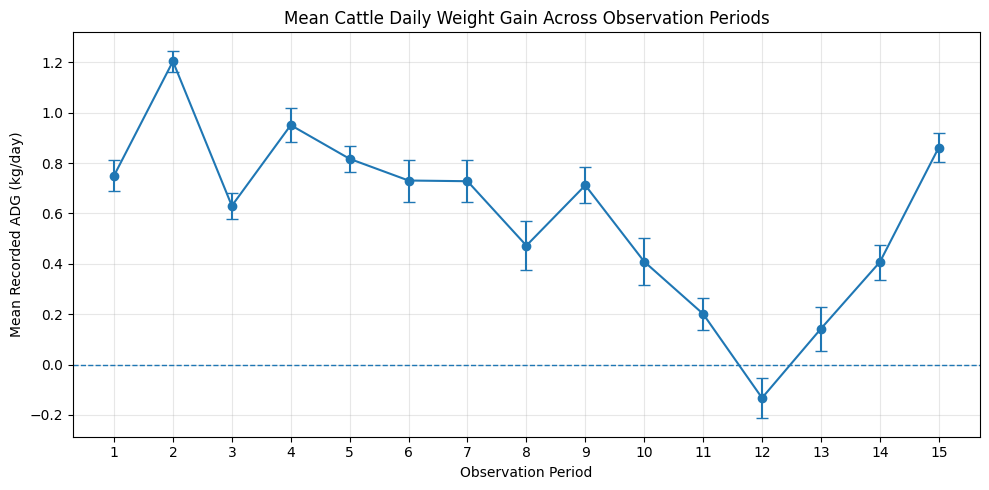

In [12]:
# Description: Plot mean recorded ADG across the 15 observation periods.

import matplotlib.pyplot as plt

growth_by_period = (
    df.groupby("PERIOD")["ADG_recorded"]
      .agg(["mean", "std", "count"])
      .reset_index()
)

growth_by_period["SE"] = (
    growth_by_period["std"] / growth_by_period["count"]**0.5
)

plt.figure(figsize=(10, 5))
plt.errorbar(
    growth_by_period["PERIOD"],
    growth_by_period["mean"],
    yerr=growth_by_period["SE"],
    marker="o",
    capsize=4
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Observation Period")
plt.ylabel("Mean Recorded ADG (kg/day)")
plt.title("Mean Cattle Daily Weight Gain Across Observation Periods")
plt.xticks(growth_by_period["PERIOD"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Figure 1 interpretation:** Mean recorded ADG varied across the 15 observation periods, reaching its highest value in Period 2 (approximately 1.20 kg/day) and its lowest in Period 12 (approximately −0.13 kg/day). Growth generally declined during the middle-to-later periods before recovering toward the end of the study. The negative mean in Period 12 indicates average weight loss during that period. These temporal variations provide context for examining associations between cattle growth, supplement-feeder behaviour, and environmental conditions. The pattern alone does not establish the causes of growth changes.

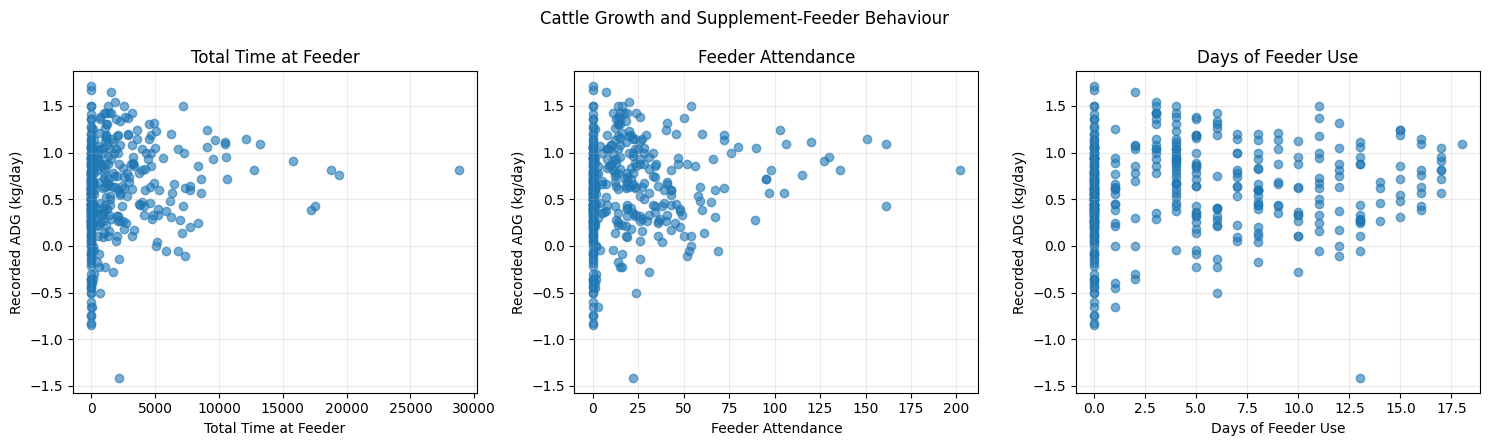

In [13]:
# Description: Plot recorded ADG against the three feeder-behaviour measures.

import matplotlib.pyplot as plt

feeder_variables = [
    ("TOTAL_TIME", "Total Time at Feeder"),
    ("TOTAL_ATTENDANCE", "Feeder Attendance"),
    ("TOTAL_DAYS", "Days of Feeder Use")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (variable, label) in zip(axes, feeder_variables):
    ax.scatter(df[variable], df["ADG_recorded"], alpha=0.6)
    ax.set_xlabel(label)
    ax.set_ylabel("Recorded ADG (kg/day)")
    ax.set_title(label)
    ax.grid(alpha=0.25)

fig.suptitle("Cattle Growth and Supplement-Feeder Behaviour")
plt.tight_layout()
plt.show()

**Figure 2 interpretation:** The scatter plots show substantial variation in recorded ADG across levels of total time at the feeder, feeder attendance, and days of feeder use. No strong linear relationship is visually apparent. These patterns are consistent with the fixed-effects analyses, which found no statistically significant associations between the three feeder-behaviour measures and ADG after controlling for animal and period differences. However, the scatter plots alone do not establish whether an association exists, and the results should be interpreted in conjunction with the statistical models.

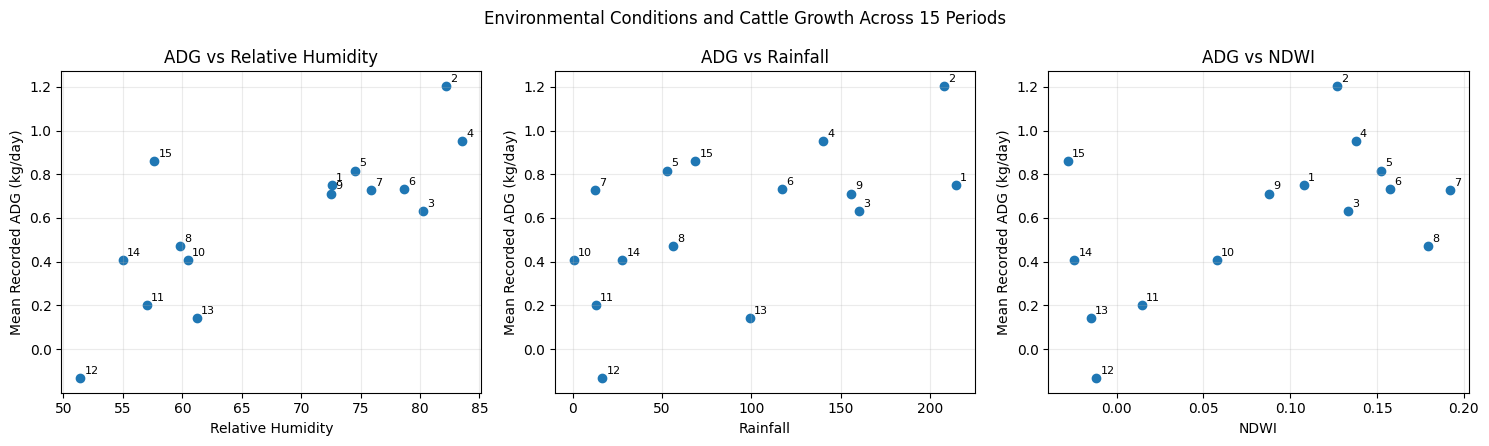

In [14]:
# Description: Plot period-level mean ADG against the three environmental variables.

import matplotlib.pyplot as plt

environmental_variables = [
    ("HUM_REL_AVG", "Relative Humidity"),
    ("RAIN_SUM", "Rainfall"),
    ("NDWI_INDEX", "NDWI")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (variable, label) in zip(axes, environmental_variables):
    ax.scatter(period_data[variable], period_data["Mean_ADG"])

    for _, row in period_data.iterrows():
        ax.annotate(
            str(int(row["PERIOD"])),
            (row[variable], row["Mean_ADG"]),
            fontsize=8,
            xytext=(3, 3),
            textcoords="offset points"
        )

    ax.set_xlabel(label)
    ax.set_ylabel("Mean Recorded ADG (kg/day)")
    ax.set_title(f"ADG vs {label}")
    ax.grid(alpha=0.25)

fig.suptitle("Environmental Conditions and Cattle Growth Across 15 Periods")
plt.tight_layout()
plt.show()


**Figure 3 interpretation:** Period-level scatter plots show positive initial associations between mean recorded ADG and relative humidity, rainfall, and NDWI. After accounting for linear time trends, the association with relative humidity remained positive and statistically significant (r = 0.6138, p = 0.0149). The time-adjusted associations with rainfall (r = 0.3103, p = 0.2604) and NDWI (r = 0.1640, p = 0.5592) were not statistically significant. These findings indicate that relative humidity warrants further investigation, but the small number of periods limits the strength of the conclusions. The results are observational and do not establish causation.

# Conclusion

This study examined associations between cattle growth, supplement-feeder behaviour, and environmental conditions in 26 Nelore cattle observed over 15 periods.

Mean recorded average daily gain varied considerably across periods, including a period of average weight loss. After controlling for animal and period differences, total time at the feeder, feeder attendance, and days of feeder use showed no statistically significant associations with recorded ADG in the fitted models.

At the period level, relative humidity, rainfall, and NDWI were initially positively correlated with mean ADG. After accounting for linear time trends, only relative humidity retained a statistically significant positive association. Rainfall and NDWI did not remain statistically significant.

These findings should be interpreted cautiously because the environmental analysis included only 15 periods, and the observational design cannot establish causation. Overall, the analysis identifies temporal variation in cattle growth and a preliminary association between relative humidity and growth, while finding insufficient evidence of independent associations between the examined feeder-behaviour measures and ADG.

